# Maintenance scheduling for a hospital medical-technology department

This notebook walks through one full planning run on **synthetic data**
generated by `scripts/generate_synthetic_data.py`. The real SAP PM export
of the hospital cannot be published; the synthetic workbook reproduces its
schema and its messiness, not its content.

Run once before executing this notebook:

```bash
python scripts/generate_synthetic_data.py
```

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import os; os.chdir(ROOT)

import pandas as pd
from maintenance_scheduler.config import Config
from maintenance_scheduler.pipeline import prepare, run, compare_modes

config = Config.load('config/config.yaml')
config.planning

PlanningConfig(keep_statuses=['EEGB', 'EHEQ'], excluded_groups=['M', 'MEDT-FRE', 'M-ISM', 'M-IM'], external_groups=['MEDT-FRE', 'M-ISM', 'M-IM'], default_duration_hours=0.5, external_duration_marker=['fremd', 'Fremd'], max_lead_days=30, batching_window_days=30, default_daily_hours=4.0)

## 1. From 45 000 raw SAP rows to a schedulable task list

Two thirds of the export is not schedulable work. Every filter is explicit
and counted, so the planner can see what was dropped and why.

In [2]:
tasks, context, cleaning, external = prepare(config)

print(f'raw rows            {cleaning.initial_rows:,}')
print(f'schedulable tasks   {cleaning.final_rows:,}')
print(f'external provider   {len(external):,}')
cleaning.to_frame()

raw rows            45,000
schedulable tasks   27,486
external provider   6,081


,filter,rows_removed
0,status not actionable (simulated / deactivated),12105
1,external provider or unassigned group,5409
2,missing due date,0
3,outside the planning horizon,0


## 2. The planning context

Teams, their daily maintenance capacity, the working calendar and the
absences. Capacity is *not* the working day: only part of the shift is
planned maintenance, the rest is reserved for unplanned repairs.

In [3]:
pd.DataFrame([
    {
        'team': name,
        'technicians': len(team.technicians),
        'daily_hours_per_technician': team.daily_hours,
        'tasks': sum(t.technician_group == name for t in tasks),
    }
    for name, team in context.teams.items()
])

,team,technicians,daily_hours_per_technician,tasks
0,M-0100,2,4.0,3312
1,M-0200,2,4.0,2443
2,M-0300,5,4.0,5680
3,M-0400,2,4.0,3478
4,M-0500,5,4.0,7001
5,M-0600,2,4.0,2766
6,M-0700,3,4.0,2290
7,M-1000,1,4.0,516


## 3. Two scheduling policies on the same data

`technician` assigns a named owner to every task; `team` plans pooled team
capacity and lets the team lead dispatch on the day. Same constraints, same
ordering - only the resource granularity differs.

In [4]:
compare_modes(config)

mode,technician,team
tasks_total,27486.0000,27486.0000
tasks_scheduled,26763.0000,26778.0000
tasks_unscheduled,723.0000,708.0000
coverage_rate,0.9737,0.9742
on_time_rate,0.7126,0.7153
on_time_rate_metrological,0.7157,0.7179
mean_days_before_due,9.9800,10.4300
scheduled_hours,15918.3000,15937.4000
available_hours,20072.0000,20072.0000
utilisation_rate,0.7931,0.7940


## 4. The batching trade-off

Inside a due-date window, tasks are re-ordered by building to cut walking
time. The longer the window, the fewer building changes per day - and the
less deadline slack is left. The window length is a configuration value
precisely because this is a business decision, not a technical one.

In [5]:
from maintenance_scheduler.metrics import evaluate
from maintenance_scheduler.scheduling.team import schedule_by_team

rows = []
for window in [1, 7, 14, 30, 60]:
    context.batching_window_days = window
    metrics = evaluate(schedule_by_team(tasks, context), context)
    rows.append({
        'window_days': window,
        'building_switches_per_day': metrics.building_switches_per_day,
        'on_time_rate': metrics.on_time_rate,
        'coverage_rate': metrics.coverage_rate,
    })
context.batching_window_days = config.planning.batching_window_days
pd.DataFrame(rows)

,window_days,building_switches_per_day,on_time_rate,coverage_rate
0,1,9.842,0.7476,0.9740
1,7,4.671,0.7400,0.9741
2,14,3.757,0.7294,0.9743
3,30,3.480,0.7153,0.9742
4,60,3.873,0.7281,0.9740


## 5. Full run: Excel deliverables, metrics and charts

The plan is consumed in Excel by people who do not use Python, so the
export is part of the product: one sheet per resource, German headers,
deadline column colour-coded, metrological controls highlighted.

In [6]:
result = run(config, mode='team')
pd.Series(result.metrics.to_dict())

mode                            team
tasks_total                    27486
tasks_scheduled                26778
tasks_unscheduled                708
coverage_rate                 0.9742
on_time_rate                  0.7153
on_time_rate_metrological     0.7179
mean_days_before_due           10.43
scheduled_hours              15937.4
available_hours              20072.0
utilisation_rate               0.794
working_days_used                256
building_switches_per_day       3.48
tasks_per_resource_day         14.33
dtype: object

## 6. Where the capacity actually goes

The tasks that could not be placed are not an error - they are the
measured capacity gap, and they are exported as their own list for the
department head.

In [7]:
from maintenance_scheduler.metrics import workload_by_resource

display(workload_by_resource(result.schedule))
display(
    pd.Series([t.technician_group for t in result.schedule.unscheduled])
    .value_counts()
    .rename('unscheduled_tasks')
)

,resource,tasks,hours,days_used,on_time_rate
0,M-0500,7001,4162.4,239,0.835
1,M-0300,5680,3375.5,237,0.961
2,M-0100,3130,1841.1,256,0.136
3,M-0400,2952,1774.1,243,0.143
4,M-0600,2766,1660.4,240,0.698
5,M-0200,2443,1451.3,237,0.948
6,M-0700,2290,1358.1,236,0.979
7,M-1000,516,314.5,181,0.988


M-0400    526
M-0100    182
Name: unscheduled_tasks, dtype: int64

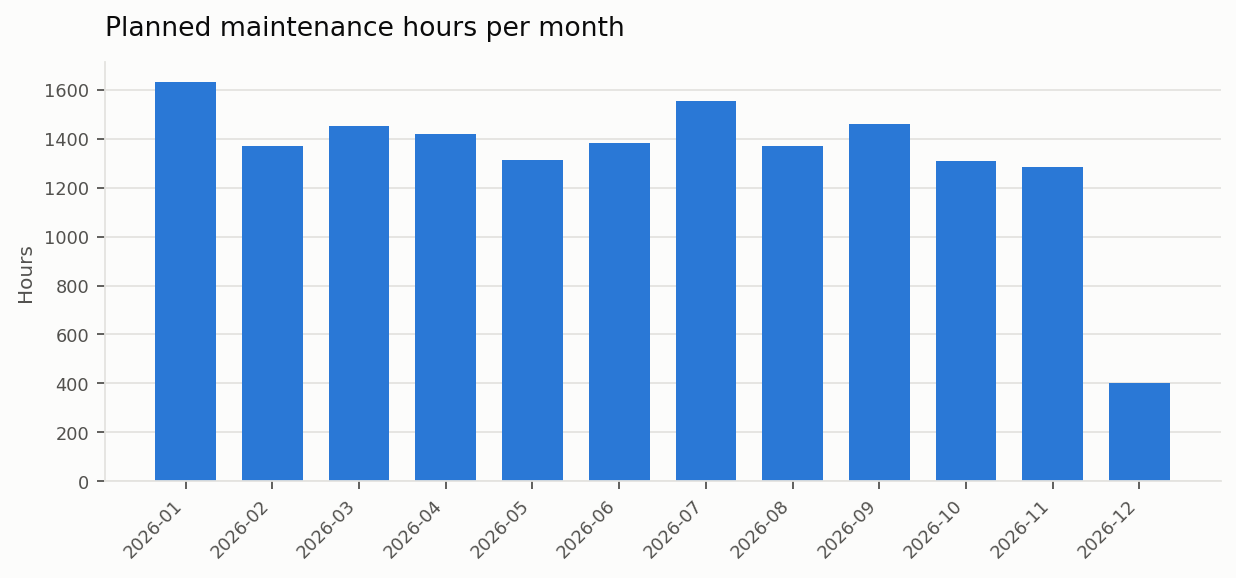

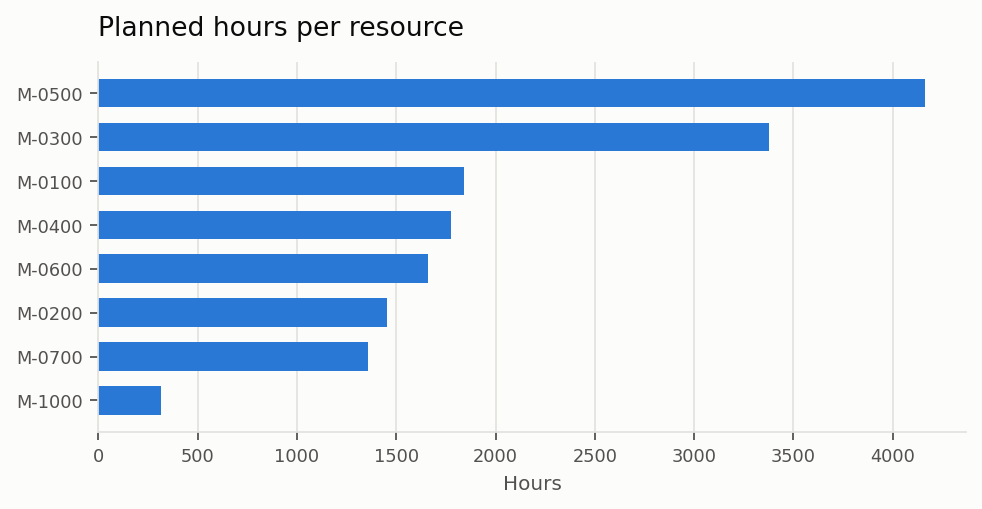

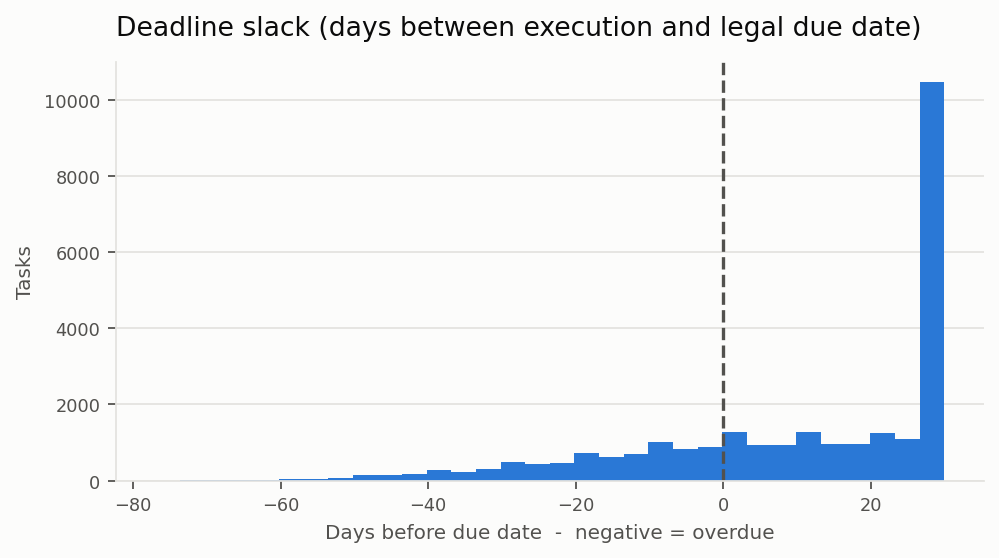

In [8]:
from IPython.display import Image, display

for name in ['monthly_load', 'workload_by_resource', 'deadline_slack']:
    display(Image(f'docs/images/{name}.png'))